In [4]:
# Load the data and look at the first rows
import pandas as pd
train = pd.read_csv("Train (1).csv")
test = pd.read_csv("Test.csv")
train.head()

,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive
0,ID_1FE951BD,Rural,Male,2007-10-02,30.0,21.137037,25.569017,18.451642,0.951601,0.584646,33.546344,"Izimba, Iganga, Uganda",1
1,ID_5927A443,Rural,Male,2008-01-05,2.0,24.062790,29.312026,18.977212,0.053352,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1
2,ID_C4E67025,Rural,Female,2008-02-14,31.0,22.407868,26.746058,18.112977,0.090349,0.573420,33.483655,"Buluza, Iganga, Uganda",1
3,ID_44DC5CE9,Rural,Female,2008-02-15,1.0,23.315198,28.056889,18.955708,0.286814,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1
4,ID_33C677BB,Rural,Female,2008-02-15,69.0,23.315198,28.056889,18.955708,0.286814,1.072343,34.226647,"Magada, Mbale City, Bugisa sub-region, Eastern...",0


In [7]:
# Check column types and missing values
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 3146 entries, 0 to 3145
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    3146 non-null   str    
 1   zone                  3146 non-null   str    
 2   gender                3146 non-null   str    
 3   deathdate             3146 non-null   str    
 4   age                   3146 non-null   float64
 5   avg_temperature       3146 non-null   float64
 6   max_temperature       3146 non-null   float64
 7   min_temperature       3146 non-null   float64
 8   precipitation         3146 non-null   float64
 9   latitude              3146 non-null   float64
 10  longitude             3146 non-null   float64
 11  location              3146 non-null   str    
 12  is_climate_sensitive  3146 non-null   int64  
dtypes: float64(7), int64(1), str(5)
memory usage: 556.2 KB


In [8]:
# Count how many rows are in each class of the target
print(train['is_climate_sensitive'].value_counts())
print(train['is_climate_sensitive'].value_counts(normalize=True))

is_climate_sensitive
1    2047
0    1099
Name: count, dtype: int64
is_climate_sensitive
1    0.650668
0    0.349332
Name: proportion, dtype: float64


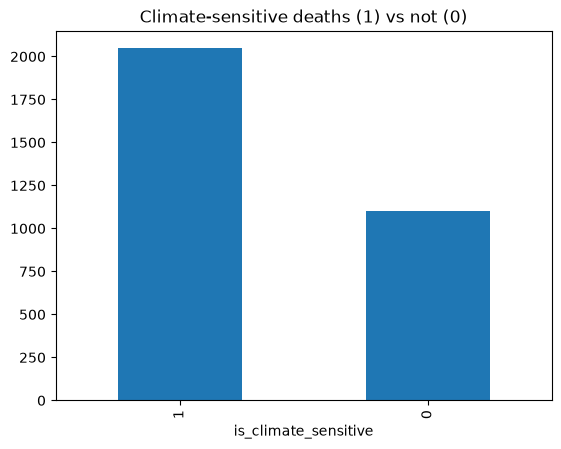

In [9]:
# Plot the target classes as a bar chart
import matplotlib.pyplot as plt
train['is_climate_sensitive'].value_counts().plot(kind='bar')
plt.title('Climate-sensitive deaths (1) vs not (0)')
plt.show()

In [10]:
# Summary statistics of age
train['age'].describe()

count    3146.000000
mean       24.243484
std        31.428833
min         0.000000
25%         0.000000
50%         3.000000
75%        49.000000
max       110.000000
Name: age, dtype: float64

In [11]:
# Compare age between the two classes
train.groupby('is_climate_sensitive')['age'].describe()

,count,mean,std,min,25%,50%,75%,max
is_climate_sensitive,,,,,,,,
0,1099.0,43.253867,33.198445,0.0,4.0,46.0,74.0,106.0
1,2047.0,14.037128,25.070645,0.0,0.0,1.0,16.5,110.0


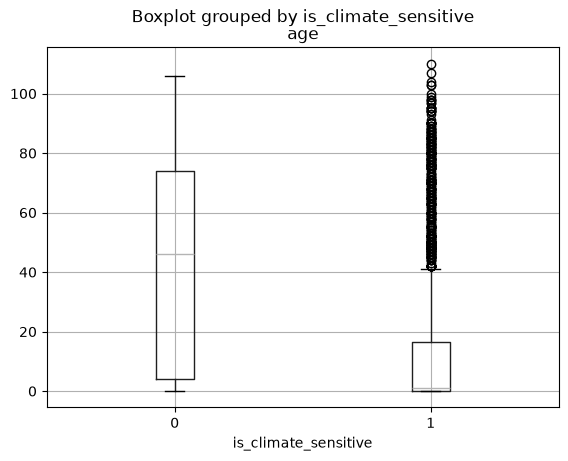

In [12]:
# Boxplot of age for each class
train.boxplot(column='age', by='is_climate_sensitive')
plt.show()

In [13]:
# How many rows have age 0, split by class
print((train['age'] == 0).groupby(train['is_climate_sensitive']).sum())

is_climate_sensitive
0    236
1    876
Name: age, dtype: int64


In [14]:
# Share of class 1 within each age group
train['age_group'] = pd.cut(train['age'], bins=[-1, 0, 5, 17, 40, 65, 120])
train.groupby('age_group')['is_climate_sensitive'].agg(['count', 'mean'])

,count,mean
age_group,,
"(-1, 0]",1112,0.787770
"(0, 5]",644,0.919255
"(5, 17]",116,0.586207
"(17, 40]",369,0.528455
"(40, 65]",351,0.438746
"(65, 120]",554,0.292419


In [15]:
# Share of class 1 within each zone
train.groupby('zone')['is_climate_sensitive'].agg(['count', 'mean'])

,count,mean
zone,,
Peri_urban,1174,0.640545
Rural,1972,0.656694


In [16]:
# Share of class 1 within each gender
train.groupby('gender')['is_climate_sensitive'].agg(['count', 'mean'])

,count,mean
gender,,
Female,1501,0.671552
Male,1645,0.631611


In [17]:
# Find the 10 most common locations
top = train['location'].value_counts().head(10).index
top

Index(['Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Eastern Region, Uganda',
       'Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Uganda',
       'Magada, Mbale City, Bugisa sub-region, Eastern Region, Uganda',
       'Bulumwaki Church of Uganda Primary School, Kaliro Road, Nkono I, Nkono, Bulumwaki I, Iganga, Eastern Region, Uganda',
       'Nawanzu, Iganga, Uganda',
       'Kabila, Kasonga, Kikuube, Western Region, Uganda',
       'Nawansinge, Iganga, Uganda', 'Wairama, Iganga, Uganda',
       'Nakigo Ii, Iganga, Uganda', 'Kasokoso South, Iganga, Uganda'],
      dtype='str', name='location')

In [18]:
# Keep only those rows, then compare class 1 share
small = train[train['location'].isin(top)]
small.groupby('location')['is_climate_sensitive'].agg(['count', 'mean'])

,count,mean
location,,
"Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Eastern Region, Uganda",211,0.639810
"Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Uganda",207,0.623188
"Bulumwaki Church of Uganda Primary School, Kaliro Road, Nkono I, Nkono, Bulumwaki I, Iganga, Eastern Region, Uganda",155,0.632258
"Kabila, Kasonga, Kikuube, Western Region, Uganda",128,0.648438
"Kasokoso South, Iganga, Uganda",114,0.701754
"Magada, Mbale City, Bugisa sub-region, Eastern Region, Uganda",158,0.639241
"Nakigo Ii, Iganga, Uganda",116,0.706897
"Nawansinge, Iganga, Uganda",120,0.658333
"Nawanzu, Iganga, Uganda",146,0.691781


In [19]:
# Number of different location names
train['location'].nunique()

39

In [20]:
# How many locations have fewer than 10 rows
counts = train['location'].value_counts()
print((counts < 10).sum())

3


In [21]:
# Check coordinates for the two Brac Uganda spellings
brac = train[train['location'].str.contains('Brac Uganda')]
brac.groupby('location')[['latitude', 'longitude']].nunique()

,latitude,longitude
location,,
"Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Eastern Region, Uganda",1,1
"Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Uganda",1,1


In [22]:
# Show the coordinates of each Brac Uganda spelling
brac.groupby('location')[['latitude', 'longitude']].first()

,latitude,longitude
location,,
"Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Eastern Region, Uganda",0.608396,33.482668
"Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Uganda",0.608396,33.482668


In [23]:
# Count distinct coordinate pairs
train[['latitude', 'longitude']].drop_duplicates().shape[0]

43

In [24]:
# Count coordinate pairs per location
pairs = train.groupby('location')[['latitude', 'longitude']].nunique()
pairs[(pairs['latitude'] > 1) | (pairs['longitude'] > 1)]

,latitude,longitude
location,,
"Nakavule B, Iganga, Uganda",2,2
"Nawanzu, Iganga, Uganda",2,2
"Wairama, Iganga, Uganda",2,2
"Walanga, Bugweri, Uganda",2,2
"Wante, Bugweri, Uganda",2,2


In [25]:
# Convert deathdate to a real date and extract year and month
train['deathdate'] = pd.to_datetime(train['deathdate'])
train['year'] = train['deathdate'].dt.year
train['month'] = train['deathdate'].dt.month

In [26]:
# Share of class 1 within each year
train.groupby('year')['is_climate_sensitive'].agg(['count', 'mean'])

,count,mean
year,,
2007,1,1.000000
2008,113,0.796460
2009,444,0.770270
2010,334,0.769461
2011,319,0.658307
2012,246,0.703252
2013,270,0.562963
2014,189,0.687831
2015,192,0.614583


In [27]:
# Share of class 1 within each month
train.groupby('month')['is_climate_sensitive'].agg(['count', 'mean'])

,count,mean
month,,
1,261,0.693487
2,249,0.650602
3,233,0.596567
4,252,0.678571
5,305,0.662295
6,314,0.652866
7,275,0.665455
8,262,0.641221
9,227,0.612335


In [28]:
# Average age and share of age-0 deaths in each year
train.groupby('year')['age'].agg(['mean', 'median'])

,mean,median
year,,
2007,30.000000,30.0
2008,29.734513,20.0
2009,23.121622,2.0
2010,24.922156,3.0
2011,28.006270,8.0
2012,26.739837,3.0
2013,32.407407,26.0
2014,29.253968,15.0
2015,31.109375,4.0


In [29]:
# Which years appear in the test file
test['year'] = pd.to_datetime(test['deathdate']).dt.year
test['year'].value_counts().sort_index()

year
2007      1
2008     27
2009    159
2010    116
2011    103
2012     84
2013     91
2014     62
2015     67
2016     63
2017     19
2018     18
2019     49
2020     59
2021     89
2022     23
Name: count, dtype: int64

In [30]:
# Share of class 1 by year, for children aged 0 to 5 only
young = train[train['age'] <= 5]
young.groupby('year')['is_climate_sensitive'].agg(['count', 'mean'])

,count,mean
year,,
2008,55,0.909091
2009,255,0.960784
2010,186,0.962366
2011,154,0.941558
2012,134,0.932836
2013,118,0.906780
2014,88,0.977273
2015,98,0.928571
2016,85,0.964706


In [31]:
# Summary statistics of the climate columns
train[['avg_temperature', 'max_temperature', 'min_temperature', 'precipitation']].describe()

,avg_temperature,max_temperature,min_temperature,precipitation
count,3146.000000,3146.000000,3146.000000,3146.000000
mean,22.066541,26.206879,18.514193,1.519907
std,1.095122,1.691347,0.891524,1.621088
min,18.852803,20.884623,15.018778,0.000000
25%,21.319885,25.260527,17.954814,0.286814
50%,21.931299,26.081829,18.510478,1.034344
75%,22.652860,27.015877,19.040655,2.222345
max,27.012223,34.080947,21.849602,16.606523


In [32]:
# Average of each climate column for each class
train.groupby('is_climate_sensitive')[['avg_temperature', 'max_temperature', 'min_temperature', 'precipitation']].mean()

,avg_temperature,max_temperature,min_temperature,precipitation
is_climate_sensitive,,,,
0,22.110776,26.289257,18.531646,1.458528
1,22.042792,26.162652,18.504822,1.552860
